# M2: Conditioning integration

COCO caption → SD tokenizer → SD Transformer hidden states → selected-token scaling → U-Net cross-attention → iterative denoising → VAE image.

SD 1.5 uses its own token-level text representations for conditioning. We reuse the M1 checkpoint and COCO subset and modify selected token vectors during inference; no parameters are trained.


In [1]:
import json
import p2_pipeline as p2
import p2_experiments as m2

cfg = m2.settings()
data_config = p2.load_config(m2.ROOT / "config.json")
data_config["dataset_dir"] = cfg["dataset_dir"]
run = m2.safe_run_dir(cfg["smoke_dir"], data_config)


In [2]:
if (run / "summary.json").is_file():
    manifest_sha256 = p2.read_json(run / "run_signature.json")["manifest_sha256"]
    prompts = p2.read_json(m2.path_from_root(cfg["prompts_file"]))
else:
    manifest_sha256 = p2.verify_dataset(data_config)["manifest_sha256"]
    prompts = m2.fixed_inputs(cfg, data_config)
print({"pairs": data_config["dataset_size"], "manifest": manifest_sha256})
for p in prompts:
    print(p["index"], p["seed"], cfg["spans"][str(p["index"])] , "|", p["prompt"])


{'pairs': 1200, 'manifest': 'b6683d25acda660cce6a95e049b6561f515f08a9ad072e8c260cf75e10759de8'}
1 7615 fire hydrant | A blue fire hydrant posed on a street corner in a city.
2 7616 pizza slice | A child taking a bite of a pizza slice on a plate.
3 7617 Two computers | Two computers are sitting on top of the desk.
4 7618 clock | a large tower that has a big clock at top
5 7619 men | An orange truck driving down a street full of men in the back.
6 7620 fallen tree branches | Animals trying to either move or go around fallen tree branches
7 7621 surfing | A person that is surfing in the water.
8 7622 motorcycle | A man standing with his motorcycle outside of a repair shop.
9 7623 giraffe | A giraffe has come to a fence line to greet visitors.
10 7624 red train | A long red train traveling through snow covered country side.
11 7625 throw a pitch | A baseball player preparing to throw a pitch during a game.
12 7626 flying disc | A dog laying on grass near a flying disc.


## Controlled modification

For a declared span, `H'[0, i, :] = w H[0, i, :]`, with `w = 1.2`. Other token vectors and the empty negative condition remain unchanged. BOS, EOS and padding are excluded; span positions are checked against the full caption's BPE sequence.

Prompts 1 (fire hydrant) and 12 (flying disc) use their original seeds, PNDM, guidance 7.5 and 30 requested steps. The three paths use the raw prompt, explicit embeddings at weight 1, and explicit embeddings at weight 1.2. The first two agree on the final latent. The weighted path changes the latent, and the U-Net input check confirms that it receives the intended condition. The displayed samples come from the original signed run.


In [3]:
result = m2.smoke(cfg, data_config)
print(json.dumps(result, indent=2))
print("Comparison samples:", result["sample_count"])


{
  "status": "passed",
  "phase": "smoke",
  "checks": [
    {
      "prompt_id": 1,
      "manual_encoding_exact": true,
      "identity_latents_exact": true,
      "modified_latents_differ": true,
      "image_hashes": {
        "raw": "7ced26bae5af8ac3406d2f62b50dc8a1a1c4cb0bf59f388628fa8e24e1cf149b",
        "explicit": "7ced26bae5af8ac3406d2f62b50dc8a1a1c4cb0bf59f388628fa8e24e1cf149b",
        "modified": "63808ee1bc31c7bbc0f2f2bfe5da4376845eb625baf9324b1ddaf8b793b1dd4f"
      },
      "max_abs_modified_latent_change": 3.3818359375
    },
    {
      "prompt_id": 12,
      "manual_encoding_exact": true,
      "identity_latents_exact": true,
      "modified_latents_differ": true,
      "image_hashes": {
        "raw": "0ad7f5989da67ecee3788e86262bb262ad4c07bcdf2a64bc4e52544b334016f2",
        "explicit": "0ad7f5989da67ecee3788e86262bb262ad4c07bcdf2a64bc4e52544b334016f2",
        "modified": "ec10260e5a2fa332389bfae135db37b52dbaa6bcc0c00317b7184c966c7bab22"
      },
      "max_abs_

A blue fire hydrant posed on a street corner in a city. | seed 7615
raw {'seconds': 5.145005851984024, 'peak_allocated_gib': 3.071295738220215, 'unet_calls': 31}
explicit {'seconds': 2.124790843576193, 'peak_allocated_gib': 3.071295738220215, 'unet_calls': 31}
modified {'seconds': 2.1257827430963516, 'peak_allocated_gib': 3.071295738220215, 'unet_calls': 31}
{'span': 'fire hydrant', 'token_indices': [3, 4, 5], 'shape': [1, 77, 768], 'negative_shape': [1, 77, 768], 'max_abs_change': 1.18359375}
U-Net CFG input: {'shape': [2, 77, 768], 'matches_expected': True}
Weighted BPE pieces: ['fire</w>', 'hydr', 'ant</w>']
A dog laying on grass near a flying disc. | seed 7626
raw {'seconds': 2.1363648045808077, 'peak_allocated_gib': 3.071295738220215, 'unet_calls': 31}
explicit {'seconds': 2.1262832079082727, 'peak_allocated_gib': 3.071295738220215, 'unet_calls': 31}
modified {'seconds': 2.127973945811391, 'peak_allocated_gib': 3.071295738220215, 'unet_calls': 31}
{'span': 'flying disc', 'token_in

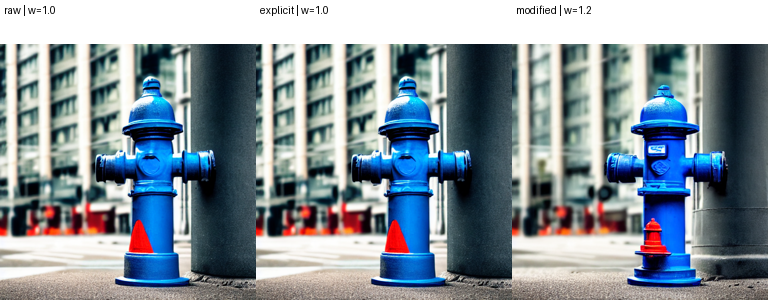

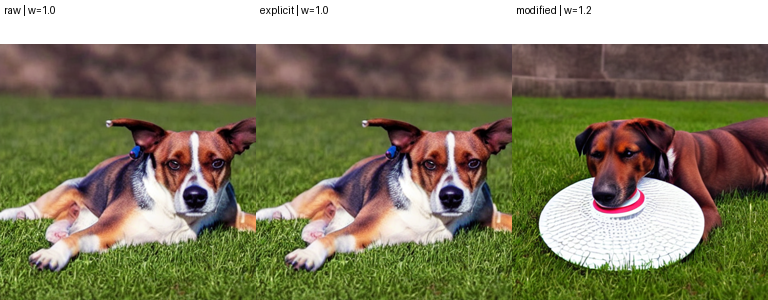

In [4]:
from IPython.display import display
from PIL import Image, ImageDraw

run = m2.path_from_root(cfg["smoke_dir"])
for index in cfg["smoke_prompt_ids"]:
    prompt = next(p for p in prompts if p["index"] == index)
    print(prompt["prompt"], "| seed", prompt["seed"])
    sheet = Image.new("RGB", (256 * len(m2.SMOKE_MODES), 300), "white")
    draw = ImageDraw.Draw(sheet)
    for i, mode in enumerate(m2.SMOKE_MODES):
        r = p2.read_json(run / "generated" / f"{index:02d}_{mode}.json")
        with Image.open(run / r["image"]) as image:
            sheet.paste(image.resize((256, 256)), (i * 256, 44))
        label = f"{mode} | w={r['condition']['weight']}"
        if r["nsfw_content_detected"]:
            label += " FLAGGED"
        draw.text((i * 256 + 4, 4), label, fill="black")
        print(mode, {k: r[k] for k in ("seconds", "peak_allocated_gib", "unet_calls")})
    display(sheet)
    r = p2.read_json(run / "generated" / f"{index:02d}_modified.json")
    print({k: r["condition"][k] for k in ("span", "token_indices", "shape", "negative_shape", "max_abs_change")})
    print("U-Net CFG input:", r["unet_condition"])
    print("Weighted BPE pieces:", [r["condition"]["tokens"][i] for i in r["condition"]["token_indices"]])


In [5]:
import numpy as np

r = p2.read_json(run / "generated" / "12_modified.json")
with np.load(run / r["diagnostics"], allow_pickle=False) as trace:
    print("Columns:", r["diagnostic_columns"])
    print("First/last diagnostics:", trace["stats"][[0, -1]])
print("Requested steps:", r["inputs"]["configuration"]["steps"])
print("Actual timesteps:", r["timesteps"])


Columns: ['latent_rms', 'latent_std', 'update_rms', 'finite']
First/last diagnostics: [[1.0063401  1.0063664  0.         1.        ]
 [0.9339154  0.91635686 0.00293475 1.        ]]
Requested steps: 30
Actual timesteps: [958, 925, 925, 892, 859, 826, 793, 760, 727, 694, 661, 628, 595, 562, 529, 496, 463, 430, 397, 364, 331, 298, 265, 232, 199, 166, 133, 100, 67, 34, 1]


## Diagnostics

The saved diagnostics contain latent RMS, standard deviation, update RMS, finite-value checks, runtime and peak allocated memory. The first inference call may include warm-up overhead. A changed trajectory establishes the intervention's effect, while image quality and alignment require visual evaluation.

